# Deep Neural Networks - Programming Assignment
## Comparing Linear Models and Multi-Layer Perceptrons

**Student Name:** ____VANSHIKA SAXENA____  
**Student ID:** ________2025AC05606________  
**Date:**____31-05-2026____

---

## ⚠️ IMPORTANT INSTRUCTIONS

1. **Complete ALL sections** marked with `TODO`
2. **DO NOT modify** the `get_assignment_results()` function structure
3. **Fill in all values accurately** - these will be auto-verified
4. **After submission**, you'll receive a verification quiz based on YOUR results
5. **Run all cells** before submitting (Kernel → Restart & Run All)

---

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
import time
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)
print('✓ Libraries imported successfully')

✓ Libraries imported successfully


## Section 1: Dataset Selection and Loading

**Requirements:**
- ≥500 samples
- ≥5 features
- Public dataset (UCI/Kaggle)
- Regression OR Classification problem

In [2]:
# TODO: Load your dataset
# Example: data = pd.read_csv('your_dataset.csv')
data = pd.read_csv("ObesityDataSet.csv")
# Dataset information (TODO: Fill these)
dataset_name = "Obesity Levels Dataset"  # e.g., "Breast Cancer Wisconsin"
dataset_source = "UCI Machine Learning Repository"  # e.g., "UCI ML Repository"
n_samples = data.shape[0]     # Total number of rows
n_features = data.shape[1]-1     # Number of features (excluding target)
problem_type = "multiclass_classification"  # "regression" or "binary_classification" or "multiclass_classification"

# Problem statement (TODO: Write 2-3 sentences)
problem_statement = """
This dataset predicts obesity levels based on eating habits,physical activity and lifestyle characteristics.
The target variable contains seven obesity categories, making this a multi-class classification problem. 
"""

# Primary evaluation metric (TODO: Fill this)
primary_metric = "F1-score"  # e.g., "recall", "accuracy", "rmse", "r2"

# Metric justification (TODO: Write 2-3 sentences)
metric_justification = """
I have chosen F1-score as primary evaluation metric because it balances both precision and recall.
"""

print(f"Dataset: {dataset_name}")
print(f"Source: {dataset_source}")
print(f"Samples: {n_samples}, Features: {n_features}")
print(f"Problem Type: {problem_type}")
print(f"Primary Metric: {primary_metric}")

Dataset: Obesity Levels Dataset
Source: UCI Machine Learning Repository
Samples: 2111, Features: 16
Problem Type: multiclass_classification
Primary Metric: F1-score


## Section 2: Data Preprocessing

Preprocess your data:
1. Handle missing values
2. Encode categorical variables
3. Split into train/test sets
4. Scale features

In [3]:
# TODO: Preprocess your data
# 1. Separate features (X) and target (y)
X = data.drop('NObeyesdad', axis=1)
y = data['NObeyesdad']

# 2. Handle missing values if any
if data.isnull().sum().sum() > 0:
    data = data.dropna()
    
# 3. Encode categorical variables
categorical_columns = X.select_dtypes(include=['object']).columns
feature_encoders = {}
for column in categorical_columns:
    encoder = LabelEncoder()
    X[column] = encoder.fit_transform(X[column])
    feature_encoders[column] = encoder

target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y)

# Example:
# X = data.drop('target', axis=1)
# y = data['target']

# TODO: Train-test split
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# TODO: Feature scaling
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fill these after preprocessing
train_samples = len(X_train)      # Number of training samples
test_samples = len(X_test)        # Number of test samples
train_test_ratio = train_samples / (train_samples + test_samples)  # e.g., 0.8 for 80-20 split

print(f"Train samples: {train_samples}")
print(f"Test samples: {test_samples}")
print(f"Split ratio: {train_test_ratio:.1%}")

Train samples: 1688
Test samples: 423
Split ratio: 80.0%


## Section 3: Baseline Model Implementation

Implement from scratch (NO sklearn models!):
- Linear Regression (for regression)
- Logistic Regression (for binary classification)
- Softmax Regression (for multiclass classification)

**Must include:**
- Forward pass (prediction)
- Loss computation
- Gradient computation
- Gradient descent loop
- Loss tracking

In [4]:
class BaselineModel:
    """
    Baseline linear model with gradient descent
    Implement: Linear/Logistic/Softmax Regression
    """
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []
    
    def fit(self, X, y):
        """
        TODO: Implement gradient descent training
        
        Steps:
        1. Initialize weights and bias
        2. For each iteration:
           a. Compute predictions (forward pass)
           b. Compute loss
           c. Compute gradients
           d. Update weights and bias
           e. Store loss in self.loss_history
        
        Must populate self.loss_history with loss at each iteration!
        """
        n_samples, n_features = X.shape
        
        # TODO: Initialize parameters
        n_classes=len(np.unique(y))
        self.weights = np.zeros((n_features, n_classes))
        self.bias = np.zeros((1, n_classes))
        
        y_onehot = np.eye(n_classes)[y]
        # TODO: Implement gradient descent loop
        for i in range(self.n_iterations):
            # 1. Forward pass: y_pred = ...
            linear_output = np.dot(X, self.weights) + self.bias
            exp_values = np.exp(linear_output - np.max(linear_output, axis=1, keepdims=True))
            y_pred = exp_values / np.sum(exp_values,axis=1,keepdims=True)
            # 2. Compute loss
            loss = -np.mean(np.sum(y_onehot * np.log(y_pred + 1e-15),axis=1))
            # 3. Compute gradients: dw = ..., db = ...
            dw = (1 / n_samples) * np.dot(X.T,(y_pred - y_onehot))
            db = (1 / n_samples) * np.sum((y_pred - y_onehot),axis=0,keepdims=True)     
            # 4. Update: self.weights -= self.lr * dw
            self.weights -= self.lr * dw
            self.bias -= self.lr * db   
            # 5. self.loss_history.append(loss)
            self.loss_history.append(loss)    
            
        
        return self
    
    def predict(self, X):
        """
        TODO: Implement prediction
        
        For regression: return linear_output
        For classification: return class probabilities or labels
        """
        linear_output = np.dot(X, self.weights) + self.bias
        exp_values = np.exp(linear_output - np.max(linear_output, axis=1, keepdims=True))
        probabilities = exp_values / np.sum(exp_values,axis=1,keepdims=True)
        return np.argmax(probabilities, axis=1)

print("✓ Baseline model class defined")

✓ Baseline model class defined


In [5]:
# Train baseline model
print("Training baseline model...")
baseline_start_time = time.time()

# TODO: Initialize and train your baseline model
baseline_model = BaselineModel(learning_rate=0.01, n_iterations=1000)
baseline_model.fit(X_train_scaled, y_train)

# TODO: Make predictions
baseline_predictions = baseline_model.predict(X_test_scaled)

baseline_training_time = time.time() - baseline_start_time
print(f"✓ Baseline training completed in {baseline_training_time:.2f}s")
print(f"✓ Loss decreased from {baseline_model.loss_history[0]:.4f} to {baseline_model.loss_history[-1]:.4f}")

Training baseline model...
✓ Baseline training completed in 3.05s
✓ Loss decreased from 1.9459 to 1.0713


## Section 4: Multi-Layer Perceptron Implementation

Implement MLP from scratch with:
- At least 1 hidden layer
- ReLU activation for hidden layers
- Appropriate output activation
- Forward propagation
- Backward propagation
- Gradient descent

In [6]:
class MLP:
    """
    Multi-Layer Perceptron implemented from scratch
    """
    def __init__(self, architecture, learning_rate=0.01, n_iterations=1000):
        """
        architecture: list [input_size, hidden1, hidden2, ..., output_size]
        Example: [30, 16, 8, 1] means:
            - 30 input features
            - Hidden layer 1: 16 neurons
            - Hidden layer 2: 8 neurons
            - Output layer: 1 neuron
        """
        self.architecture = architecture
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.parameters = {}
        self.loss_history = []
        self.cache = {}
    
    def initialize_parameters(self):
        """
        TODO: Initialize weights and biases for all layers
        
        For each layer l:
        - W[l]: weight matrix of shape (n[l], n[l-1])
        - b[l]: bias vector of shape (n[l], 1)
        
        Store in self.parameters dictionary
        """
        np.random.seed(42)
        
        for l in range(1, len(self.architecture)):
            # TODO: Initialize weights and biases
            # self.parameters[f'W{l}'] = ...
            self.parameters[f'W{l}'] = np.random.randn(self.architecture[l-1],self.architecture[l])* np.sqrt(2.0 / self.architecture[l-1])
            # self.parameters[f'b{l}'] = ...
            self.parameters[f'b{l}'] = np.zeros((1, self.architecture[l]))
       
    
    def relu(self, Z):
        """ReLU activation function"""
        return np.maximum(0, Z)
    
    def relu_derivative(self, Z):
        """ReLU derivative"""
        return (Z > 0).astype(float)
    
    def sigmoid(self, Z):
        """Sigmoid activation (for binary classification output)"""
        return 1 / (1 + np.exp(-np.clip(Z, -500, 500)))
    
    def forward_propagation(self, X):
        """
        TODO: Implement forward pass through all layers
        
        For each layer:
        1. Z[l] = W[l] @ A[l-1] + b[l]
        2. A[l] = activation(Z[l])
        
        Store Z and A in self.cache for backpropagation
        Return final activation A[L]
        """
        self.cache['A0'] = X
        
        # TODO: Implement forward pass
        # for l in range(1, len(self.architecture)):
        #     ...
        
        A = X
        L = len(self.architecture) - 1
        for l in range(1, L):
            W = self.parameters[f'W{l}']
            b = self.parameters[f'b{l}']
            Z = np.dot(A, W) + b
            A = self.relu(Z)
            self.cache[f'Z{l}'] = Z
            self.cache[f'A{l}'] = A
 
        W = self.parameters[f'W{L}']
        b = self.parameters[f'b{L}']
        ZL = np.dot(A, W) + b
        exp_values = np.exp(ZL - np.max(ZL, axis=1, keepdims=True))
        AL = exp_values / np.sum(exp_values,axis=1,keepdims=True)
        self.cache[f'Z{L}'] = ZL
        self.cache[f'A{L}'] = AL

        return AL
    
    def backward_propagation(self, X, y):
        """
        TODO: Implement backward pass to compute gradients
        
        Starting from output layer, compute:
        1. dZ[l] for each layer
        2. dW[l] = dZ[l] @ A[l-1].T / m
        3. db[l] = sum(dZ[l]) / m
        
        Return dictionary of gradients
        """
        m = X.shape[0]
        grads = {}
        
        # TODO: Implement backward pass
        # Start with output layer gradient
        # Then propagate backwards through hidden layers
        L = len(self.architecture) - 1
        n_classes = self.architecture[-1]
        y_onehot = np.eye(n_classes)[y]
        AL = self.cache[f'A{L}']        
        dZ = AL - y_onehot
        grads[f'dW{L}'] = (np.dot(self.cache[f'A{L-1}'].T, dZ)) / m
        grads[f'db{L}'] = (np.sum(dZ, axis=0, keepdims=True)) / m
        for l in reversed(range(1, L)):
            dA = np.dot(dZ,self.parameters[f'W{l+1}'].T)
            dZ = dA * self.relu_derivative(self.cache[f'Z{l}'])
            if l == 1:
                A_prev = X
            else:
                A_prev = self.cache[f'A{l-1}']
            grads[f'dW{l}'] = (np.dot(A_prev.T, dZ)) / m
            grads[f'db{l}'] = (np.sum(dZ, axis=0, keepdims=True)) / m       
        
        
        return grads
    
    def update_parameters(self, grads):
        """
        TODO: Update weights and biases using gradients
        
        For each layer:
        W[l] = W[l] - learning_rate * dW[l]
        b[l] = b[l] - learning_rate * db[l]
        """
        # TODO: Implement parameter updates
        L = len(self.architecture) - 1
        for l in range(1, L + 1):
            self.parameters[f'W{l}'] -= (self.lr * grads[f'dW{l}'])
            self.parameters[f'b{l}'] -= (self.lr * grads[f'db{l}'])
            
    
    def compute_loss(self, y_pred, y_true):
        """
        TODO: Compute loss
        
        For regression: MSE
        For classification: Cross-entropy
        """
        n_classes = self.architecture[-1]
        y_onehot = np.eye(n_classes)[y_true]
        loss = -np.mean(np.sum(y_onehot * np.log(y_pred + 1e-15),axis=1))
        return loss
    
    def fit(self, X, y):
        """
        TODO: Implement training loop
        
        For each iteration:
        1. Forward propagation
        2. Compute loss
        3. Backward propagation
        4. Update parameters
        5. Store loss
        
        Must populate self.loss_history!
        """
        self.initialize_parameters()
        
        for i in range(self.n_iterations):
            # TODO: Training loop
            y_pred = self.forward_propagation(X)
            loss = self.compute_loss(y_pred,y)
            grads = self.backward_propagation(X,y)
            self.update_parameters(grads)
            self.loss_history.append(loss)
            
        
        return self
    
    def predict(self, X):
        """
        TODO: Implement prediction
        
        Use forward_propagation and apply appropriate thresholding
        """
        y_pred = self.forward_propagation(X)
        return np.argmax(y_pred,axis=1)


print("✓ MLP class defined")

✓ MLP class defined


In [7]:
# Train MLP
print("Training MLP...")
mlp_start_time = time.time()

# TODO: Define your architecture and train MLP
mlp_architecture = [ X_train_scaled.shape[1], # 16 input features
    32,
    16,
    len(np.unique(y_train))  ]  # Example: [n_features, 16, 8, 1]
mlp_model = MLP(architecture=mlp_architecture, learning_rate=0.01, n_iterations=1000)
mlp_model.fit(X_train_scaled, y_train)

# TODO: Make predictions
mlp_predictions = mlp_model.predict(X_test_scaled)

mlp_training_time = time.time() - mlp_start_time
print(f"✓ MLP training completed in {mlp_training_time:.2f}s")
print(f"✓ Loss decreased from {mlp_model.loss_history[0]:.4f} to {mlp_model.loss_history[-1]:.4f}")


Training MLP...
✓ MLP training completed in 9.96s
✓ Loss decreased from 2.9090 to 0.8421


## Section 5: Evaluation and Metrics

Calculate appropriate metrics for your problem type

In [8]:
def calculate_metrics(y_true, y_pred, problem_type):
    """
    TODO: Calculate appropriate metrics based on problem type
    
    For regression: MSE, RMSE, MAE, R²
    For classification: Accuracy, Precision, Recall, F1
    """
    metrics = {}
    
    if problem_type == "regression":
        # TODO: Calculate regression metrics
        mse = np.mean((y_true - y_pred) ** 2)
        rmse = np.sqrt(mse)
        mae = np.mean(np.abs(y_true - y_pred))
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        r2 = 1 - (ss_res / ss_tot)
        metrics = {
            "mse": mse,
            "rmse": rmse,
            "mae": mae,
            "r2": r2}
        
    elif problem_type in ["binary_classification", "multiclass_classification"]:
        # TODO: Calculate classification metric
        accuracy = np.mean(y_true == y_pred)
        classes = np.unique(y_true)
        precision_list = []
        recall_list = []
        f1_list = []
        for cls in classes:
            tp = np.sum((y_true == cls) & (y_pred == cls))
            fp = np.sum((y_true != cls) & (y_pred == cls))
            fn = np.sum((y_true == cls) & (y_pred != cls))
            precision = tp / (tp + fp + 1e-15)
            recall = tp / (tp + fn + 1e-15)
            f1 = (2 * precision * recall /(precision + recall + 1e-15))
            precision_list.append(precision)
            recall_list.append(recall)
            f1_list.append(f1)

        metrics = {
            "accuracy": accuracy,
            "precision": np.mean(precision_list),
            "recall": np.mean(recall_list),
            "f1": np.mean(f1_list)        }
    
    return metrics

# Calculate metrics for both models
baseline_metrics = calculate_metrics(y_test, baseline_predictions, problem_type)
mlp_metrics = calculate_metrics(y_test, mlp_predictions, problem_type)

print("Baseline Model Performance:")
print(baseline_metrics)

print("\nMLP Model Performance:")
print(mlp_metrics)

Baseline Model Performance:
{'accuracy': np.float64(0.6264775413711584), 'precision': np.float64(0.5925125934343983), 'recall': np.float64(0.6201560435550583), 'f1': np.float64(0.5849125220724221)}

MLP Model Performance:
{'accuracy': np.float64(0.6690307328605201), 'precision': np.float64(0.6540371279252197), 'recall': np.float64(0.6614337040445415), 'f1': np.float64(0.6405750251867647)}


## Section 6: Visualization

Create visualizations:
1. Training loss curves
2. Performance comparison
3. Additional domain-specific plots

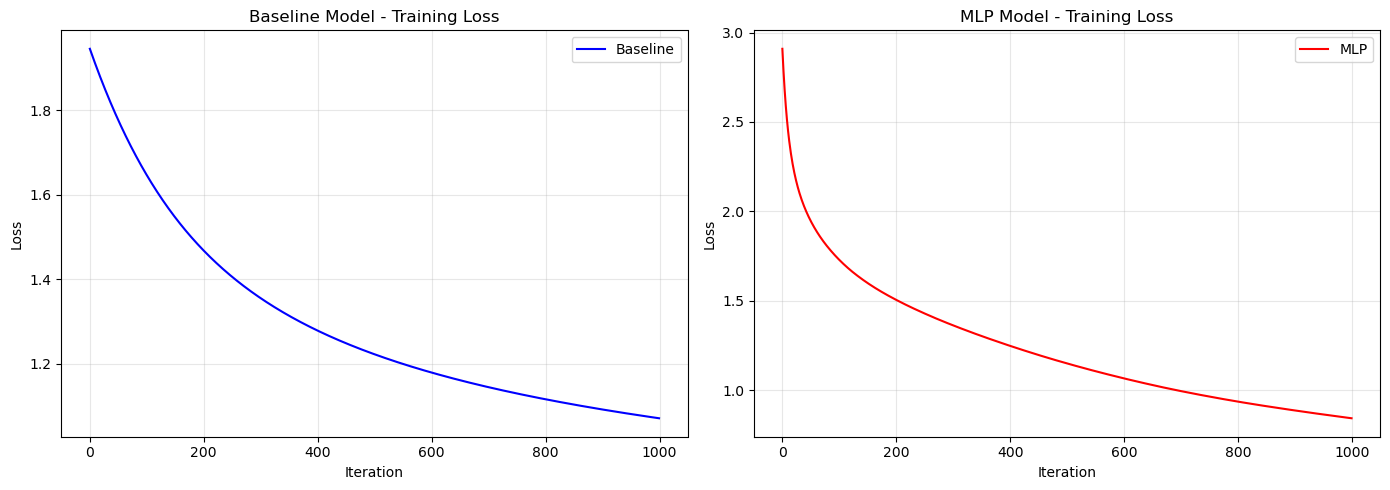

In [9]:
# 1. Training loss curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
# TODO: Plot baseline loss
plt.plot(baseline_model.loss_history, label='Baseline', color='blue')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Baseline Model - Training Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
# TODO: Plot MLP loss
plt.plot(mlp_model.loss_history, label='MLP', color='red')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('MLP Model - Training Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

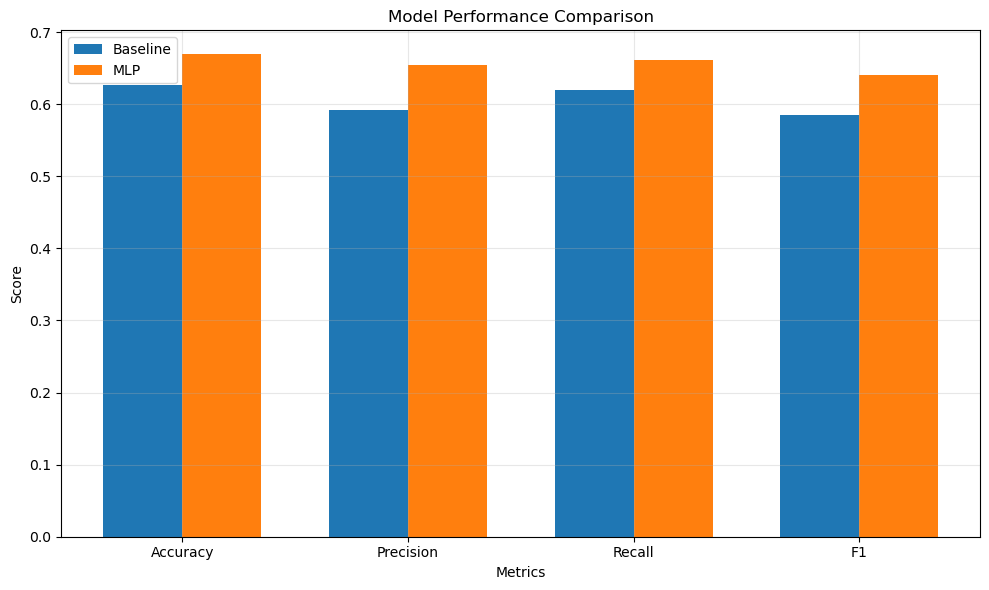

In [10]:
# 2. Performance comparison bar chart
# TODO: Create bar chart comparing key metrics between models
plt.figure(figsize=(10, 6))
metrics = ['accuracy', 'precision', 'recall', 'f1']
baseline_scores = [
    baseline_metrics['accuracy'],
    baseline_metrics['precision'],
    baseline_metrics['recall'],
    baseline_metrics['f1']
]

mlp_scores = [
    mlp_metrics['accuracy'],
    mlp_metrics['precision'],
    mlp_metrics['recall'],
    mlp_metrics['f1']
]
x = np.arange(len(metrics))
width = 0.35
plt.bar(
    x - width/2,
    baseline_scores,
    width,
    label='Baseline'
)
plt.bar(
    x + width/2,
    mlp_scores,
    width,
    label='MLP'
)
plt.xlabel('Metrics')
plt.ylabel('Score')
plt.title('Model Performance Comparison')
plt.xticks(x,['Accuracy', 'Precision', 'Recall', 'F1'])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Section 7: Analysis and Discussion

Write your analysis (minimum 200 words)

In [11]:
analysis_text = """
In this assignment, I compared a baseline Softmax Regression model with a Multi-Layer Perceptron (MLP) on the Obesity Levels Dataset, which is a multi-class classification problem with seven classes. The baseline model achieved an accuracy of 62.65%, precision of 59.25%, recall of 62.02%, and F1-score of 0.5849. The MLP achieved an accuracy of 66.90%, precision of 65.40%, recall of 66.14%, and F1-score of 0.6406. Therefore, the MLP outperformed the baseline model on all evaluation metrics. The improvement was approximately 4.25% in accuracy and 5.57% in F1-score.
The main reason for the better performance of the MLP is its ability to learn non-linear relationships between input features and target classes. Obesity levels depend on multiple factors such as eating habits, physical activity, and lifestyle choices, which are unlikely to be separated by simple linear decision boundaries. Softmax Regression can only model linear relationships, while the MLP can learn more complex patterns through hidden layers and non-linear activation functions.
There was also a difference in computational cost. The baseline model trained faster, while the MLP required more training time because of forward propagation, backpropagation, and parameter updates across multiple layers. A challenge encountered during implementation was poor convergence caused by weight initialization. Initially, the network predicted only one class and achieved very low accuracy. After switching to He initialization, the training loss decreased significantly from 2.9090 to 0.8421 and the model learned effectively.
This assignment helped me understand the differences between linear models and neural networks. While linear models are simpler and computationally efficient, neural networks are more powerful for capturing complex patterns and can achieve better predictive performance when implemented correctly.
"""

print(f"Analysis word count: {len(analysis_text.split())} words")
if len(analysis_text.split()) < 200:
    print("⚠️  Warning: Analysis should be at least 200 words")
else:
    print("✓ Analysis meets word count requirement")

Analysis word count: 270 words
✓ Analysis meets word count requirement


---
---

## ⭐ REQUIRED: Structured Output Function

### **DO NOT MODIFY THE STRUCTURE BELOW**

This function will be called by the auto-grader. Fill in all values accurately based on your actual results.

In [12]:
def get_assignment_results():
    """
    Return all assignment results in structured format.
    
    CRITICAL: Fill in ALL values based on your actual results!
    This will be automatically extracted and validated.
    """
    
    # Calculate loss convergence flags
    baseline_initial_loss = float(baseline_model.loss_history[0])  # TODO: baseline_model.loss_history[0]
    baseline_final_loss = float(baseline_model.loss_history[-1])    # TODO: baseline_model.loss_history[-1]
    mlp_initial_loss = float(mlp_model.loss_history[0])    # TODO: mlp_model.loss_history[0]
    mlp_final_loss = float(mlp_model.loss_history[-1])       # TODO: mlp_model.loss_history[-1]
    total_parameters = 0
    for i in range(len(mlp_architecture) - 1):
        total_parameters += (mlp_architecture[i] *mlp_architecture[i + 1])
        total_parameters += mlp_architecture[i + 1]    
        
    results = {
        # ===== Dataset Information =====
        'dataset_name': dataset_name,
        'dataset_source': dataset_source,
        'n_samples': n_samples,
        'n_features': n_features,
        'problem_type': problem_type,
        'problem_statement': problem_statement,
        
        # ===== Evaluation Setup =====
        'primary_metric': primary_metric,
        'metric_justification': metric_justification,
        'train_samples': train_samples,
        'test_samples': test_samples,
        'train_test_ratio': train_test_ratio,
        
        # ===== Baseline Model Results =====
        'baseline_model': {
            'model_type': 'softmax_regression',  # 'linear_regression', 'logistic_regression', or 'softmax_regression'
            'learning_rate': baseline_model.lr,
            'n_iterations': baseline_model.n_iterations,
            'initial_loss': baseline_initial_loss,
            'final_loss': baseline_final_loss,
            'training_time_seconds': baseline_training_time,
            
            # Metrics (fill based on your problem type)
            'test_accuracy': float(baseline_metrics['accuracy']),      # For classification
            'test_precision': float(baseline_metrics['precision']),     # For classification
            'test_recall': float(baseline_metrics['recall']),        # For classification
            'test_f1': float(baseline_metrics['f1']),            # For classification
            'test_mse': 0.0,           # For regression
            'test_rmse': 0.0,          # For regression
            'test_mae': 0.0,           # For regression
            'test_r2': 0.0,            # For regression
        },
        
        # ===== MLP Model Results =====
        'mlp_model': {
            'architecture': mlp_architecture,
            'n_hidden_layers': len(mlp_architecture) - 2 if len(mlp_architecture) > 0 else 0,
            'total_parameters': total_parameters,     # TODO: Calculate total weights + biases
            'learning_rate': mlp_model.lr,
            'n_iterations':  mlp_model.n_iterations,
            'initial_loss': mlp_initial_loss,
            'final_loss': mlp_final_loss,
            'training_time_seconds': mlp_training_time,
            
            # Metrics
            'test_accuracy': float( mlp_metrics['accuracy']),
            'test_precision':  float(mlp_metrics['precision']),
            'test_recall':  float(mlp_metrics['recall']),
            'test_f1':  float(mlp_metrics['f1']),
            'test_mse': 0.0,
            'test_rmse': 0.0,
            'test_mae': 0.0,
            'test_r2': 0.0,
        },
        
        # ===== Comparison =====
        'improvement':   float(mlp_metrics['f1'] -baseline_metrics['f1']),            # MLP primary_metric - baseline primary_metric
        'improvement_percentage': float(((mlp_metrics['f1'] - baseline_metrics['f1']) / baseline_metrics['f1']) * 100),  # (improvement / baseline) * 100
        'baseline_better': bool( baseline_metrics['f1'] > mlp_metrics['f1']),  # True if baseline outperformed MLP
        
        # ===== Analysis =====
        'analysis': analysis_text,
        'analysis_word_count': len(analysis_text.split()),
        
        # ===== Loss Convergence Flags =====
        'baseline_loss_decreased': baseline_final_loss < baseline_initial_loss,
        'mlp_loss_decreased': mlp_final_loss < mlp_initial_loss,
        'baseline_converged': baseline_final_loss <baseline_initial_loss,  # Optional: True if converged
        'mlp_converged':  mlp_final_loss <mlp_initial_loss,
    }
    
    return results



## Test Your Output

Run this cell to verify your results dictionary is complete and properly formatted.

In [13]:
# Test the output
import json

try:
    results = get_assignment_results()
    
    print("="*70)
    print("ASSIGNMENT RESULTS SUMMARY")
    print("="*70)
    print(json.dumps(results, indent=2, default=str))
    print("\n" + "="*70)
    
    # Check for missing values
    missing = []
    def check_dict(d, prefix=""):
        for k, v in d.items():
            if isinstance(v, dict):
                check_dict(v, f"{prefix}{k}.")
            elif (v == 0 or v == "" or v == 0.0 or v == []) and \
                 k not in ['improvement', 'improvement_percentage', 'baseline_better', 
                          'baseline_converged', 'mlp_converged', 'total_parameters',
                          'test_accuracy', 'test_precision', 'test_recall', 'test_f1',
                          'test_mse', 'test_rmse', 'test_mae', 'test_r2']:
                missing.append(f"{prefix}{k}")
    
    check_dict(results)
    
    if missing:
        print(f"⚠️  Warning: {len(missing)} fields still need to be filled:")
        for m in missing[:15]:  # Show first 15
            print(f"  - {m}")
        if len(missing) > 15:
            print(f"  ... and {len(missing)-15} more")
    else:
        print("✅ All required fields are filled!")
        print("\n🎉 You're ready to submit!")
        print("\nNext steps:")
        print("1. Kernel → Restart & Clear Output")
        print("2. Kernel → Restart & Run All")
        print("3. Verify no errors")
        print("4. Save notebook")
        print("5. Rename as: YourStudentID_assignment.ipynb")
        print("6. Submit to LMS")
        
except Exception as e:
    print(f"❌ Error in get_assignment_results(): {str(e)}")
    print("\nPlease fix the errors above before submitting.")

ASSIGNMENT RESULTS SUMMARY
{
  "dataset_name": "Obesity Levels Dataset",
  "dataset_source": "UCI Machine Learning Repository",
  "n_samples": 2111,
  "n_features": 16,
  "problem_type": "multiclass_classification",
  "problem_statement": "\nThis dataset predicts obesity levels based on eating habits,physical activity and lifestyle characteristics.\nThe target variable contains seven obesity categories, making this a multi-class classification problem. \n",
  "primary_metric": "F1-score",
  "metric_justification": "\nI have chosen F1-score as primary evaluation metric because it balances both precision and recall.\n",
  "train_samples": 1688,
  "test_samples": 423,
  "train_test_ratio": 0.7996210326859309,
  "baseline_model": {
    "model_type": "softmax_regression",
    "learning_rate": 0.01,
    "n_iterations": 1000,
    "initial_loss": 1.9459101490553068,
    "final_loss": 1.0712532327688638,
    "training_time_seconds": 3.0475940704345703,
    "test_accuracy": 0.6264775413711584,
 

---

## 📤 Before Submitting - Final Checklist

- [ ] **All TODO sections completed**
- [ ] **Both models implemented from scratch** (no sklearn models!)
- [ ] **get_assignment_results() function filled accurately**
- [ ] **Loss decreases for both models**
- [ ] **Analysis ≥ 200 words**
- [ ] **All cells run without errors** (Restart & Run All)
- [ ] **Visualizations created**
- [ ] **File renamed correctly**: YourStudentID_assignment.ipynb

---

## ⏭️ What Happens Next

After submission:
1. ✅ Your notebook will be **auto-graded** (executes automatically)
2. ✅ You'll receive a **verification quiz** (10 questions, 5 minutes)
3. ✅ Quiz questions based on **YOUR specific results**
4. ✅ Final score released after quiz validation

**The verification quiz ensures you actually ran your code!**

---

**Good luck! 🚀**